<a href="https://colab.research.google.com/github/akshukla2789-source/ECI-News-Sentiment-Analysis/blob/main/ECI.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[nltk_data] Downloading package vader_lexicon to /root/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!


,publishedAt,source,title,description,url
0,2026-11-19T09:47:14Z,Business Standard,"ECI can blacklist BLAs filing fake Form 7s, bu...",Delhi SIR: Supreme Court asked the Election Co...,https://www.business-standard.com/india-news/e...
1,2026-11-19T08:12:16Z,Bar & Bench - Indian Legal News,ECI has only limited powers against BLAs who f...,ECI has only limited powers against BLAs who f...,https://www.barandbench.com/news/eci-has-only-...
2,2026-11-18T19:25:08Z,The Times of India,"Pune tops SIR pending notices list with 7,712 ...",Pune leads Maharashtra in pending SIR electora...,https://timesofindia.indiatimes.com/city/pune/...
3,2026-11-18T19:19:30Z,The Times of India,Cong terms 13-day window for ASDD voters inade...,Congress says ECI’s 13-day Nov 18–30 ASDD vote...,https://timesofindia.indiatimes.com/city/pune/...
4,2026-11-18T18:25:11Z,The Times of India,Borkar issues legal notice to Goa CEO over add...,RG MLA Viresh Borkar issues legal notice to Go...,https://timesofindia.indiatimes.com/city/goa/b...


Number of articles: 100
Dataset after cleaning:
(99, 6)
Sentiment
Positive    49
Negative    35
Neutral     15
Name: count, dtype: int64


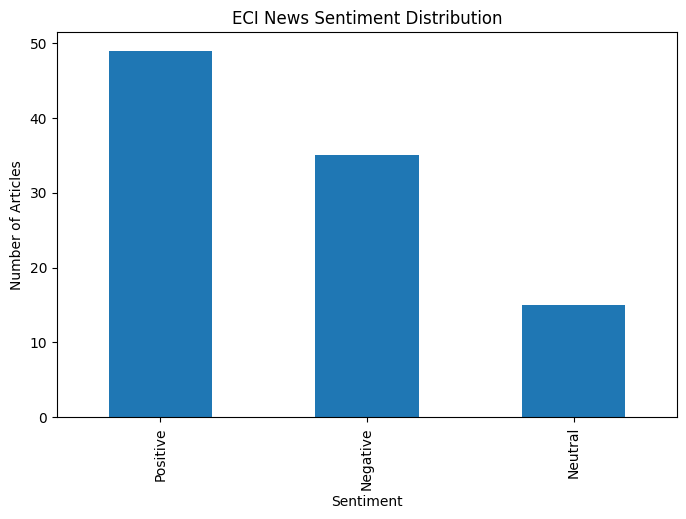

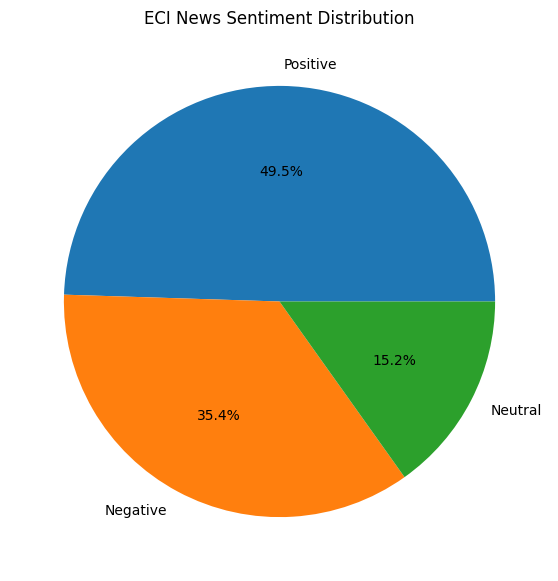

Features: (99,)
Labels: (99,)
Training samples: 79
Testing samples: 20
Training matrix: (79, 1082)
Testing matrix: (20, 1082)
Model training completed!
Predictions completed!
Model Accuracy: 50.0 %
              precision    recall  f1-score   support

    Negative       0.00      0.00      0.00         7
     Neutral       0.00      0.00      0.00         3
    Positive       0.50      1.00      0.67        10

    accuracy                           0.50        20
   macro avg       0.17      0.33      0.22        20
weighted avg       0.25      0.50      0.33        20



/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


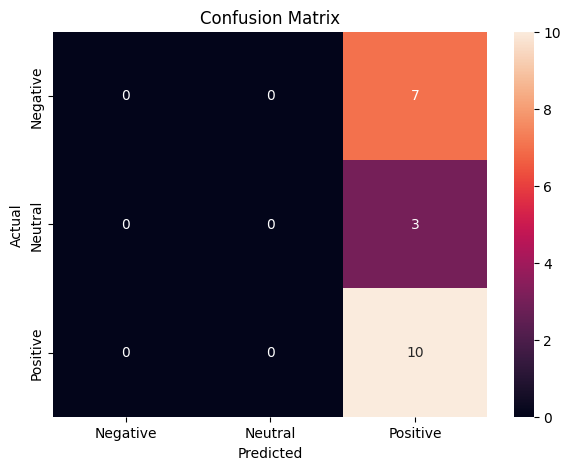

Predicted Sentiment: Positive
News: Election Commission announces new voter registration facilities
Predicted Sentiment: Positive
------------------------------------------------------------
News: ECI faces criticism over election arrangements
Predicted Sentiment: Positive
------------------------------------------------------------
News: Election Commission successfully completes polling process
Predicted Sentiment: Positive
------------------------------------------------------------
CSV file created successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,Date,Source,Title,Sentiment,Compound_Score,URL
0,2026-11-19T09:47:14Z,Business Standard,"ECI can blacklist BLAs filing fake Form 7s, bu...",Positive,0.1901,https://www.business-standard.com/india-news/e...
1,2026-11-19T08:12:16Z,Bar & Bench - Indian Legal News,ECI has only limited powers against BLAs who f...,Positive,0.6597,https://www.barandbench.com/news/eci-has-only-...
2,2026-11-18T19:25:08Z,The Times of India,"Pune tops SIR pending notices list with 7,712 ...",Positive,0.5719,https://timesofindia.indiatimes.com/city/pune/...
3,2026-11-18T19:19:30Z,The Times of India,Cong terms 13-day window for ASDD voters inade...,Negative,-0.3262,https://timesofindia.indiatimes.com/city/pune/...
4,2026-11-18T18:25:11Z,The Times of India,Borkar issues legal notice to Goa CEO over add...,Negative,-0.2732,https://timesofindia.indiatimes.com/city/goa/b...
5,2026-11-18T18:23:03Z,The Times of India,Left out of Telangana’s draft voter roll? ASDD...,Negative,-0.0516,https://timesofindia.indiatimes.com/city/hyder...
6,2026-11-18T17:07:44Z,The Times of India,Greater Bengaluru Authority announces Special ...,Positive,0.8750,https://timesofindia.indiatimes.com/city/benga...
7,2026-11-18T16:48:58Z,The Times of India,Special camps at booths highlight gaps in vote...,Positive,0.2263,https://timesofindia.indiatimes.com/city/ranch...
8,2026-11-18T15:21:32Z,BusinessLine,AI adoption puts pressure on India Inc to mode...,Positive,0.0516,https://www.thehindubusinessline.com/companies...
9,2026-11-18T13:15:30Z,The Times of India,Can Rahul & others make the Election Commissio...,Positive,0.7184,https://timesofindia.indiatimes.com/toi-plus/l...


In [2]:
!pip -q install requests pandas numpy matplotlib seaborn nltk scikit-learn
import requests
import pandas as pd
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk
import re

from nltk.sentiment import SentimentIntensityAnalyzer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

nltk.download('vader_lexicon')

API_KEY = "54447bd6b5804bd4924d17bbdf6fe062"

url = "https://newsapi.org/v2/everything"

params = {
    "q": '"Election Commission of India" OR ECI',
    "language": "en",
    "sortBy": "publishedAt",
    "pageSize": 100,
    "apiKey": API_KEY
}

response = requests.get(url, params=params)

data = response.json()

if data["status"] == "ok":
    articles = data["articles"]

    df = pd.DataFrame(articles)

    # Select useful columns
    df = df[[
        "publishedAt",
        "source",
        "title",
        "description",
        "url"
    ]]

    # Extract source name
    df["source"] = df["source"].apply(
        lambda x: x["name"] if isinstance(x, dict) else x
    )

    display(df.head())

else:
    print("Error:", data)

    articles = data["articles"]

rows = []

for article in articles:
    rows.append({
        "Date": article.get("publishedAt"),
        "Source": article.get("source", {}).get("name"),
        "Title": article.get("title"),
        "Description": article.get("description"),
        "URL": article.get("url"),
        "Content": article.get("content")
    })

df = pd.DataFrame(rows)

print("Number of articles:", len(df))

df.head()

df = df.drop_duplicates(subset=["Title"])

df = df.dropna(subset=["Title"])

df["Description"] = df["Description"].fillna("")
df["Content"] = df["Content"].fillna("")

print("Dataset after cleaning:")
print(df.shape)

df.head()

df["Text"] = (
    df["Title"].astype(str) + " " +
    df["Description"].astype(str)
)

df[["Title", "Text"]].head()

def clean_text(text):

    text = text.lower()

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove HTML
    text = re.sub(r"<.*?>", "", text)

    # Remove special characters
    text = re.sub(r"[^a-zA-Z\s]", "", text)

    # Remove extra spaces
    text = re.sub(r"\s+", " ", text).strip()

    return text


df["Clean_Text"] = df["Text"].apply(clean_text)

df[["Text", "Clean_Text"]].head()

sia = SentimentIntensityAnalyzer()

df["Compound_Score"] = df["Clean_Text"].apply(
    lambda x: sia.polarity_scores(x)["compound"]
)

df["Positive_Score"] = df["Clean_Text"].apply(
    lambda x: sia.polarity_scores(x)["pos"]
)

df["Negative_Score"] = df["Clean_Text"].apply(
    lambda x: sia.polarity_scores(x)["neg"]
)

df["Neutral_Score"] = df["Clean_Text"].apply(
    lambda x: sia.polarity_scores(x)["neu"]
)

df.head()

def get_sentiment(score):

    if score >= 0.05:
        return "Positive"

    elif score <= -0.05:
        return "Negative"

    else:
        return "Neutral"


df["Sentiment"] = df["Compound_Score"].apply(get_sentiment)

df[["Title", "Compound_Score", "Sentiment"]].head(10)

sentiment_counts = df["Sentiment"].value_counts()

print(sentiment_counts)

plt.figure(figsize=(8, 5))

df["Sentiment"].value_counts().plot(kind="bar")

plt.title("ECI News Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Articles")

plt.show()

plt.figure(figsize=(7, 7))

df["Sentiment"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%"
)

plt.title("ECI News Sentiment Distribution")

plt.ylabel("")

plt.show()

X = df["Clean_Text"]
y = df["Sentiment"]

print("Features:", X.shape)
print("Labels:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

vectorizer = TfidfVectorizer(
    max_features=5000,
    stop_words="english"
)

X_train_tfidf = vectorizer.fit_transform(X_train)

X_test_tfidf = vectorizer.transform(X_test)

print("Training matrix:", X_train_tfidf.shape)
print("Testing matrix:", X_test_tfidf.shape)

model = LogisticRegression(
    max_iter=1000
)

model.fit(
    X_train_tfidf,
    y_train
)

print("Model training completed!")

y_pred = model.predict(X_test_tfidf)

print("Predictions completed!")

accuracy = accuracy_score(
    y_test,
    y_pred
)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print(
    classification_report(
        y_test,
        y_pred
    )
)

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=["Negative", "Neutral", "Positive"]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=["Negative", "Neutral", "Positive"],
    yticklabels=["Negative", "Neutral", "Positive"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")

plt.show()

new_news = [
    "Election Commission announces new voter registration facilities"
]

new_news_clean = [
    clean_text(x) for x in new_news
]

new_news_tfidf = vectorizer.transform(
    new_news_clean
)

prediction = model.predict(
    new_news_tfidf
)

print("Predicted Sentiment:", prediction[0])

test_news = [
    "Election Commission announces new voter registration facilities",
    "ECI faces criticism over election arrangements",
    "Election Commission successfully completes polling process"
]

test_clean = [
    clean_text(x) for x in test_news
]

test_tfidf = vectorizer.transform(test_clean)

predictions = model.predict(test_tfidf)

for news, sentiment in zip(test_news, predictions):
    print("News:", news)
    print("Predicted Sentiment:", sentiment)
    print("-" * 60)

    df.to_csv(
    "ECI_News_Sentiment_Dataset.csv",
    index=False
)

print("CSV file created successfully!")

from google.colab import files

files.download(
    "ECI_News_Sentiment_Dataset.csv"
)

columns_to_show = [
    "Date",
    "Source",
    "Title",
    "Sentiment",
    "Compound_Score",
    "URL"
]

df[columns_to_show].head(20)